In [9]:
import json
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

GAP_MIN, GAP_MAX = 1.23, 3.0
REQUIRE_DIRECT = None

HERE = Path.cwd()
candidates = [HERE / "data",
              HERE,
              HERE / "nootebooks" / "data" / "data",
              HERE / "notebook" / "data"
              ]

DATA_DIR = next((p for p in candidates if (p / "Composition.csv").exists()), None)
assert DATA_DIR is not None, "Stability.csv not found. Run the extraction  notebook first."

IN_PATH = DATA_DIR / "Composition.csv"
OUT_PATH = DATA_DIR / "Bandgap.csv"
FIG_DIR = DATA_DIR.parent / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Input:", IN_PATH)
print("Output:", OUT_PATH)


Input: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Composition.csv
Output: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Bandgap.csv


In [3]:
df = pd.read_csv(IN_PATH)
print("Composition.csv shape", df.shape)
assert "band_gap" in df.columns, "band_gap column is missing from composition.csv"
print("rows with bandgap are: ", int(df["band_gap"].notna().sum()))
print("rows without band gap are:", int(df["band_gap"].isna().sum()))
df.head



Composition.csv shape (17384, 18)
rows with bandgap are:  17384
rows without band gap are: 0


<bound method NDFrame.head of        formula elements  nelements  nsites       volume   density  \
0        Ac2O3     Ac_O          2       5    91.511224  9.109130   
1        Ac2S3     Ac_S          2      40  1118.407852  6.535149   
2       AcAlO3  Ac_Al_O          3       5    57.451413  8.728230   
3        AcBr3    Ac_Br          2       8   272.928947  5.679086   
4        AcBrO  Ac_Br_O          3       6   140.139410  7.652290   
...        ...      ...        ...     ...          ...       ...   
17379  ZrTl2S3  S_Tl_Zr          3      12   312.784505  6.330170   
17380   ZrTlF5  F_Tl_Zr          3      28   418.151318  6.204504   
17381   ZrV2O7   O_V_Zr          3      40   714.217756  2.837427   
17382    ZrVF6   F_V_Zr          3       8   134.849200  3.154315   
17383   ZrZnN2  N_Zn_Zr          3       4    49.252862  6.225274   

      crystal_system space_group  formation_energy_per_atom  \
0           Trigonal       P-3m1                  -3.737668   
1         Tetra

In [10]:
has_type = "is_gap_direct" in df.columns
direct = df["is_gap_direct"].astype(str).str.strip().str.lower().eq("true") if has_type else None

print("Band gap window (eV) : ")
for lo, hi in [(0.0, 0.5), (0.5, 1.0), (1.0, 1.5), (2.0, 2.5), (2.5, 3.0), (3.0,3.5), (3.5, 5.0), (5.0,100.0)]:
    m = (df["band_gap"] >= lo) & (df["band_gap"] < hi)
    line = f" {lo:>4.1f} - {hi:<5.1f}: {int(m.sum()):>7,}"
    if has_type:
        line+= f"   (direct {int((m & direct).sum()):,} | indirect {int((m & ~direct).sum()):,})"
    print(line)

Band gap window (eV) : 
  0.0 - 0.5  :   2,557   (direct 633 | indirect 1,924)
  0.5 - 1.0  :   2,485   (direct 626 | indirect 1,859)
  1.0 - 1.5  :   2,437   (direct 723 | indirect 1,714)
  2.0 - 2.5  :   2,129   (direct 584 | indirect 1,545)
  2.5 - 3.0  :   1,591   (direct 463 | indirect 1,128)
  3.0 - 3.5  :   1,417   (direct 397 | indirect 1,020)
  3.5 - 5.0  :   2,531   (direct 855 | indirect 1,676)
  5.0 - 100.0:       0   (direct 0 | indirect 0)


In [12]:
in_window = df["band_gap"].between(GAP_MIN, GAP_MAX)
gap_df = df[in_window].copy().reset_index(drop=True)
n_window = len(gap_df)

if "is_band_direct" in gap_df.columns:
    gap_df["gap_type"] = np.where(gap_df["is_gap_direct"].astype(str).strip().str.lower().ea("true"), "direct", "indirect")
    if REQUIRE_DIRECT is not None:
        want = "direct" if REQUIRE_DIRECT else "indirect"
        gap_df = gap_df[gap_df["gap_type"] == want].reset_index(drop=True)

if {"cbm", "vbm"} <= set(gap_df.columns):
    mp_gap = gap_df["cbm"] - gap_df["vbm"]
    gap_df["mp_edge_gap_ok"] = ((mp_gap - gap_df["band_gap"]).abs() <= 0.1).where(mp_gap.notna())

print("Screening funnel")
print(f"    Composition.csv                       : {len(df):,}")
print(f"    band_gap {GAP_MIN}-{GAP_MAX} eV                 : {n_window:,}")
print(f"    after direct/indirect setting       : {len(gap_df):,}")
print(f"    removed in total                    : {len(gap_df):,}")
if "gap_type" in gap_df.columns:
    print()
    print(gap_df["gap_type"].value_count())
gap_df.head()




Screening funnel
    Composition.csv                       : 17,384
    band_gap 1.23-3.0 eV                 : 7,223
    after direct/indirect setting       : 7,223
    removed in total                    : 7,223


,formula,elements,nelements,nsites,volume,density,crystal_system,space_group,formation_energy_per_atom,energy_above_hull,is_stable,band_gap,cbm,vbm,is_gap_direct,theoretical,stability_class,n_elements,mp_edge_gap_ok
0,Ac2S3,Ac_S,2,40,1118.407852,6.535149,Tetragonal,I-42d,-2.493064,0.0,True,2.2729,7.0869,4.8140,False,True,stable,2,True
1,AcCrO3,Ac_Cr_O,3,5,61.362845,8.848788,Cubic,Pm-3m,-3.138972,0.0,True,2.0031,8.2567,6.2536,False,True,stable,3,True
2,AcGaO3,Ac_Ga_O,3,5,61.455078,9.314495,Cubic,Pm-3m,-3.063253,0.0,True,2.8959,8.1819,5.2860,False,True,stable,3,True
3,AcI3,Ac_I,2,8,465.636416,4.334420,Hexagonal,P6_3/mmc,-1.801003,0.0,True,2.5886,2.2740,-0.3146,False,True,stable,2,True
4,Ag(BCl)6,Ag_B_Cl,3,104,1920.521818,2.666186,Cubic,Pa-3,-0.952834,0.0,True,2.6955,3.0902,0.3947,True,False,stable,3,True


In [13]:
gap_df.to_csv(OUT_PATH, index=False)

summary = {
    "saved_at": datetime.now().isoformat(timespec="seconds"),
    "input_file": IN_PATH.name,
    "output_file": OUT_PATH.name,
    "gap_window_eV": [GAP_MIN, GAP_MAX],
    "require_direct": REQUIRE_DIRECT,
    "row_in": int(len(df)),
    "after_band_gap_window": int(n_window),
    "rows_kept": int(len(gap_df)),
    "gap_type_counts": {k: int(v) for k, v in gap_df["gap_type"].value_counts().items()} if "gap_type" in gap_df.columns else None,

}
(DATA_DIR / f"{OUT_PATH.stem}_summary.json").write_text(json.dumps(summary, indent=2))
print("saved:", OUT_PATH)
print(json.dumps(summary, indent=2))

saved: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Bandgap.csv
{
  "saved_at": "2026-10-28T10:34:16",
  "input_file": "Composition.csv",
  "output_file": "Bandgap.csv",
  "gap_window_eV": [
    1.23,
    3.0
  ],
  "require_direct": null,
  "row_in": 17384,
  "after_band_gap_window": 7223,
  "rows_kept": 7223,
  "gap_type_counts": null
}


<function matplotlib.pyplot.show(close=None, block=None)>

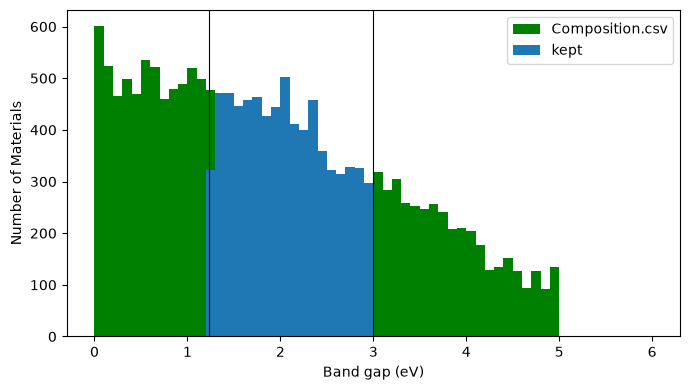

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, 6, 61)
ax.hist(df["band_gap"].clip(upper=6), bins=bins, color="green",  label="Composition.csv")
if "gap_type" in gap_df.columns:
    ax.hist(gap_df.loc[gap_df["gap_type"] == ["direct", "band_gap"], gap_df.loc[gap_df["gap_type"] == "indirect", "band_gap"]],
             bins=bins, stacked=True, color=["tab:blue", "tab:orange"], label=["kept, direct", "kept, indirect"])

else:
    ax.hist(gap_df["band_gap"], bins=bins, color="tab:blue",  label="kept")
ax.axvline(GAP_MIN, color="k", lw=0.8); ax.axvline(GAP_MAX, color="k", lw=0.8)
ax.set_xlabel("Band gap (eV)"); ax.set_ylabel("Number of Materials"); ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "bandgap_screening.png", dpi=200)
plt.show
